<a href="https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X5_ap_curling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

# Domínio V, apêndice: a pedra de curling

## Uma pedra que desliza e gira: pose, velocidade no referencial da pedra, e o arremesso que para no centro da casa

**Série:** [raiz](X0_raiz.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X0_raiz.ipynb)) · **Anterior:** [X5_dualcomplexos.ipynb](X5_dualcomplexos.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X5_dualcomplexos.ipynb))

**O jogo.** No curling, a pedra de granito (cerca de 20 kg) é lançada sobre o gelo com uma leve rotação, de uma a duas voltas por cada dez segundos, e percorre uns 28 m até a **casa**, o alvo de círculos concêntricos. Ela desacelera devagar e, enquanto isso, **curva** para o lado em que gira: girando no sentido anti-horário, curva para a esquerda, cerca de um metro no percurso todo, a maior parte no final. É o contrário do que faz um copo emborcado posto a girar e deslizar sobre uma mesa, que curva para o lado oposto.

> **Um aviso importante.** O mecanismo físico da curva da pedra de curling **não está estabelecido**: há várias explicações em disputa na literatura (assimetria do atrito entre a frente e a traseira da pedra, arranhões microscópicos no gelo, uma fina camada de água derretida), e nenhuma é consenso. Este notebook **não** resolve a questão. Ele usa um **modelo didático**, escolhido só para reproduzir os números típicos (desaceleração quase constante, curva de cerca de um metro, maior no fim), e o usa para exercitar as ferramentas do domínio. Não tire dele nenhuma conclusão sobre a física do curling.

**O modelo didático.** A pedra tem pose $q$ (posição e orientação), velocidade de translação $\mathbf v$ e velocidade angular $\omega$. A aceleração tem duas partes: um atrito de deslizamento constante, $-\mu g\,\hat{\mathbf v}$, e uma força lateral perpendicular à velocidade, para o lado do giro, que cresce quando a pedra fica lenta:

$$\dot{\mathbf v}=-\mu g\,\hat{\mathbf v}+\frac{\kappa\,\omega}{|\mathbf v|+v_c}\,i\hat{\mathbf v},\qquad\dot\omega=0\ \text{(enquanto desliza)}.$$

Com $\mu g=0{,}0864$ m/s², $\kappa=0{,}012$ m²/s² e $v_c=0{,}3$ m/s, uma pedra lançada a 2,2 m/s percorre uns 28 m e curva cerca de um metro.

**O que este notebook mostra.**
1. Duas integrações do mesmo modelo: no **mundo** (posição e velocidade como vetores) e no **grupo** (a pose $q$ avança, a cada passo, por um deslocamento rígido $q\leftarrow q\,\text{pose}(\omega\Delta t,\mathbf d)$ medido no referencial da pedra, que gira com ela; ali a velocidade gira ao contrário, $\dot u=a_{\text{corpo}}-i\omega u$). As duas concordam, e a segunda dá a orientação de graça.
2. Inverter o giro espelha a trajetória.
3. O **arremesso**: encontrar a velocidade e a direção de lançamento que fazem a pedra parar no centro da casa, por Newton.

In [1]:
# Ferramentas comuns da série (repetidas em todos os notebooks, para que cada um rode sozinho no Colab)
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "figure.dpi": 100,
                     "axes.spines.top": False, "axes.spines.right": False})

def confere(nome, obtido, esperado, tol=1e-9, relativo=False):
    """Compara duas quantidades. Imprime OK ou interrompe o notebook com uma mensagem clara."""
    a, b = np.asarray(obtido), np.asarray(esperado)
    tipo = complex if (np.iscomplexobj(a) or np.iscomplexobj(b)) else float      # aceita complexos (domínio IV)
    a, b = a.astype(tipo), b.astype(tipo)
    escala = max(np.max(np.abs(b)), 1e-300) if relativo else 1.0
    erro = float(np.max(np.abs(a - b)) / escala)
    ok = erro <= tol
    print(f"{'OK ' if ok else 'FALHOU'}  {nome}:  diferença {'relativa ' if relativo else ''}máxima = {erro:.2e}")
    assert ok, f"conferência falhou: {nome}"

def wrap(a):
    return np.pi - (np.pi - np.asarray(a, float)) % (2 * np.pi)

def sinc(x):
    """sen(x)/x, sem perder dígitos perto de 0 (np.sinc usa sen(πx)/(πx))."""
    return np.sinc(np.asarray(x, float) / np.pi)

class DC:
    """Número dual-complexo q = a + b·ε, com a = a0 + i·a1 e b = b0 + i·b1, e a regra z·ε = ε·z̄.
    Guardado como quatro reais (a0, a1, b0, b1), que podem ser floats, Fractions ou números duais."""
    def __init__(self, a0, a1, b0, b1):
        self.a0, self.a1, self.b0, self.b1 = a0, a1, b0, b1
    def __mul__(self, o):
        if not isinstance(o, DC):                       # número real vezes dual-complexo
            return DC(self.a0 * o, self.a1 * o, self.b0 * o, self.b1 * o)
        # a = a1·a2 ;  b = a1·b2 + b1·conj(a2)   (a regra z ε = ε z̄ conjuga o fator que "passa" por ε)
        a0 = self.a0 * o.a0 - self.a1 * o.a1
        a1 = self.a0 * o.a1 + self.a1 * o.a0
        b0 = (self.a0 * o.b0 - self.a1 * o.b1) + (self.b0 * o.a0 + self.b1 * o.a1)
        b1 = (self.a0 * o.b1 + self.a1 * o.b0) + (self.b1 * o.a0 - self.b0 * o.a1)
        return DC(a0, a1, b0, b1)
    __rmul__ = __mul__
    def __add__(self, o): return DC(self.a0 + o.a0, self.a1 + o.a1, self.b0 + o.b0, self.b1 + o.b1)
    def __sub__(self, o): return DC(self.a0 - o.a0, self.a1 - o.a1, self.b0 - o.b0, self.b1 - o.b1)
    def conj(self):
        """q* = ā − b ε: o inverso de um dual-complexo unitário."""
        return DC(self.a0, -self.a1, -self.b0, -self.b1)
    def norma2(self):
        """q q* = |a|² (um número real: a parte dual se cancela)."""
        return self.a0 * self.a0 + self.a1 * self.a1
    @property
    def a(self): return complex(self.a0, self.a1)
    @property
    def b(self): return complex(self.b0, self.b1)
    def __repr__(self): return f"({self.a:.6g}) + ({self.b:.6g})ε"

def pose(theta, t):
    """A pose 'girar θ, transladar t' (t complexo): q = r + (t r̄ / 2) ε, com r = e^{iθ/2}."""
    r = np.exp(0.5j * theta); b = t * np.conj(r) / 2
    return DC(r.real, r.imag, b.real, b.imag)

def angulo(q):
    return float(wrap(2 * np.arctan2(q.a1, q.a0)))

def translacao(q):
    """t = 2 b a / |a|² (vale também para q não unitário)."""
    return 2 * q.b * q.a / q.norma2()

def aplica(q, p):
    """O ponto p (complexo) levado pela pose q: a translação de q · (translação até p)."""
    return translacao(q * pose(0.0, p))

def Exp(w, v):
    """Velocidade (ω, v) no corpo, v complexo, por uma unidade de tempo: um arco de círculo (ou um segmento, se ω = 0)."""
    return pose(w, v * np.exp(0.5j * w) * sinc(w / 2))

def Log(q):
    th = angulo(q)
    return th, translacao(q) / (np.exp(0.5j * th) * sinc(th / 2))

MU_G, KAPPA, VC = 0.0864, 0.012, 0.3
ALVO = 28.35 + 0j                     # da linha de lançamento (hog line) ao centro da casa (tee), em metros

def aceleracao(v, w):
    s = abs(v); vh = v / s
    return -MU_G * vh + KAPPA * w / (s + VC) * 1j * vh

def lanca_mundo(v0, phi, w0, dt=0.01):
    """Integração no mundo: posição e velocidade como números complexos (trapézio na posição)."""
    p, v, th = 0j, v0 * np.exp(1j * phi), 0.0
    while abs(v) > MU_G * dt:
        vn = v + aceleracao(v, w0) * dt
        p += (v + vn) / 2 * dt; th += w0 * dt; v = vn
    f = abs(v) / (MU_G * dt)                    # o último pedaço de passo, até a velocidade zerar
    return p + v * f * dt / 2, th + w0 * f * dt

def lanca_grupo(v0, phi, w0, dt=0.01, guarda=False):
    """Integração no grupo: a pose q avança por q·pose(ω dt, d), com d o deslocamento no referencial da pedra.
    No referencial da pedra, que gira com velocidade ω, a velocidade gira ao contrário: u' = a_corpo − iωu."""
    q = pose(phi, 0j)                           # a pedra parte com o "nariz" na direção de lançamento
    u = v0 + 0j                                 # no referencial dela, a velocidade inicial aponta para a frente
    hist = [q]
    while abs(u) > MU_G * dt:
        a_corpo = aceleracao(u, w0)             # a aceleração do modelo só depende de v em relação a ela mesma: vale no corpo
        u_novo = np.exp(-1j * w0 * dt) * (u + a_corpo * dt)
        d = (u + (u + a_corpo * dt)) / 2 * dt   # deslocamento no referencial do início do passo (trapézio)
        q = q * pose(w0 * dt, d)                # desloca d e gira ω dt, ambos medidos no referencial da pedra
        u = u_novo
        if guarda: hist.append(q)
    f = abs(u) / (MU_G * dt)
    q = q * pose(w0 * f * dt, u * f * dt / 2)
    if guarda: hist.append(q)
    return (q, hist) if guarda else q

In [2]:
# sem a força lateral, a distância de parada é v0²/(2 μg)
KAPPA_salvo, KAPPA = KAPPA, 0.0
p_reto, _ = lanca_mundo(2.2, 0.0, 0.8)
q_reto = lanca_grupo(2.2, 0.0, 0.8)
KAPPA = KAPPA_salvo
confere("sem curva, a pedra para em v0²/(2μg) (mundo)", p_reto, 2.2**2 / (2 * MU_G), tol=1e-9)
confere("sem curva, a pedra para em v0²/(2μg) (grupo)", translacao(q_reto), 2.2**2 / (2 * MU_G), tol=1e-9)

print("  Δt      mundo                     grupo                     diferença     voltas da pedra")
for dt in [0.04, 0.02, 0.01, 0.005]:
    p, th = lanca_mundo(2.2, 0.0, 0.8, dt); q = lanca_grupo(2.2, 0.0, 0.8, dt)
    print(f"{dt:6.3f}   {p:.4f}      {translacao(q):.4f}      {abs(p - translacao(q)) * 100:6.3f} cm    {th / (2 * np.pi):.3f}")
confere("mundo e grupo concordam até o arredondamento", abs(p - translacao(q)), 0, tol=1e-9)
confere("e a orientação final é a mesma", wrap(angulo(q) - th), 0, tol=1e-9)

OK   sem curva, a pedra para em v0²/(2μg) (mundo):  diferença máxima = 7.99e-13
OK   sem curva, a pedra para em v0²/(2μg) (grupo):  diferença máxima = 1.53e-12
  Δt      mundo                     grupo                     diferença     voltas da pedra
 0.040   27.9481+1.0008j      27.9481+1.0008j       0.000 cm    3.244
 0.020   27.9480+1.0002j      27.9480+1.0002j       0.000 cm    3.243
 0.010   27.9479+0.9999j      27.9479+0.9999j       0.000 cm    3.243
 0.005   27.9479+0.9998j      27.9479+0.9998j       0.000 cm    3.243
OK   mundo e grupo concordam até o arredondamento:  diferença máxima = 1.69e-12
OK   e a orientação final é a mesma:  diferença máxima = 9.95e-14


Sem a força lateral, as duas integrações dão a distância de parada exata (com atrito constante, o trapézio é exato). Com a força lateral, elas concordam até o arredondamento, para todo $\Delta t$: não é coincidência, são **o mesmo esquema** (trapézio na posição, Euler na velocidade) escrito em dois referenciais, e o produto de poses passa de um para o outro sem perder nada. O efeito do passo aparece só na casa do milímetro: de $\Delta t=0{,}04$ s a $0{,}005$ s, o ponto de parada muda 1 mm. A pedra dá pouco mais de três voltas no percurso, perto do que se vê no jogo.

## 1. O giro decide o lado

In [3]:
p_mais, _ = lanca_mundo(2.2, 0.0, +0.8)
p_menos, _ = lanca_mundo(2.2, 0.0, -0.8)
print(f"giro anti-horário: para em {p_mais:.3f};   giro horário: para em {p_menos:.3f}")
confere("inverter o giro espelha a trajetória", p_menos, np.conj(p_mais), tol=1e-12)
confere("girando no sentido anti-horário, a pedra curva para a esquerda (y > 0)", p_mais.imag > 0, True)

giro anti-horário: para em 27.948+1.000j;   giro horário: para em 27.948-1.000j
OK   inverter o giro espelha a trajetória:  diferença máxima = 0.00e+00
OK   girando no sentido anti-horário, a pedra curva para a esquerda (y > 0):  diferença máxima = 0.00e+00


## 2. O arremesso: parar no centro da casa

O jogador escolhe o giro (anti-horário, $\omega_0=0{,}8$ rad/s) e precisa acertar a **velocidade** $v_0$ e a **direção** $\varphi$ de lançamento para que a pedra pare em cima do centro da casa. São duas incógnitas e duas equações (a posição final é um número complexo). Newton, com o jacobiano $2\times2$ por diferenças finitas: a posição final é uma função suave de $(v_0,\varphi)$, porque o último pedaço de passo é tratado exatamente.

Repare: a pedra curva para a esquerda, então o jogador tem de mirar **à direita** do alvo.

In [4]:
def fim(x):
    return translacao(lanca_grupo(x[0], x[1], 0.8))

x = np.array([2.2, 0.0])
for it in range(8):
    r = fim(x) - ALVO
    print(f"it {it}:  v0 = {x[0]:.6f} m/s,  φ = {np.degrees(x[1]):+.5f}°,  a pedra para a {abs(r) * 100:9.4f} cm do centro")
    if abs(r) < 1e-9: break
    h = 1e-6; J = np.zeros((2, 2))
    for k in range(2):
        d = np.zeros(2); d[k] = h
        df = (fim(x + d) - fim(x - d)) / (2 * h)
        J[:, k] = [df.real, df.imag]
    x = x - np.linalg.solve(J, [r.real, r.imag])
confere("o arremesso para no centro da casa (a menos de 1 mm)", abs(fim(x) - ALVO), 0, tol=1e-3)
confere("e o jogador mirou à direita do alvo (φ < 0)", x[1] < 0, True)
v0_ok, phi_ok = x
print(f"\nsensibilidade: 1 cm/s a mais em v0 leva a pedra {np.linalg.norm(J[:, 0]) * 0.01 * 100:.1f} cm adiante; "
      f"0,1° a mais em φ a desloca {np.linalg.norm(J[:, 1]) * np.radians(0.1) * 100:.1f} cm")

it 0:  v0 = 2.200000 m/s,  φ = +0.00000°,  a pedra para a  107.7753 cm do centro
it 1:  v0 = 2.214385 m/s,  φ = -2.06665°,  a pedra para a    2.1804 cm do centro
it 2:  v0 = 2.215047 m/s,  φ = -2.03848°,  a pedra para a    0.0007 cm do centro
it 3:  v0 = 2.215047 m/s,  φ = -2.03849°,  a pedra para a    0.0000 cm do centro
OK   o arremesso para no centro da casa (a menos de 1 mm):  diferença máxima = 8.86e-13
OK   e o jogador mirou à direita do alvo (φ < 0):  diferença máxima = 0.00e+00

sensibilidade: 1 cm/s a mais em v0 leva a pedra 25.6 cm adiante; 0,1° a mais em φ a desloca 4.9 cm


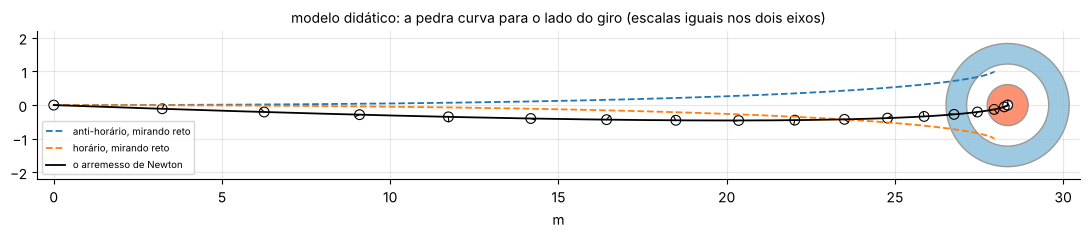

In [5]:
fig, ax = plt.subplots(figsize=(11, 3.4))
for raio, cor in [(1.83, "#9ecae1"), (1.22, "white"), (0.61, "#fc9272"), (0.15, "white")]:
    ax.add_patch(plt.Circle((ALVO.real, ALVO.imag), raio, color=cor, ec="0.6", zorder=0))
for w0, phi, v0, est, nome in [(+0.8, 0.0, 2.2, "C0--", "anti-horário, mirando reto"),
                               (-0.8, 0.0, 2.2, "C1--", "horário, mirando reto"),
                               (+0.8, phi_ok, v0_ok, "k-", "o arremesso de Newton")]:
    q_fim, hist = lanca_grupo(v0, phi, w0, guarda=True)
    pts = np.array([translacao(q) for q in hist])
    ax.plot(pts.real, pts.imag, est, lw=1.3, label=nome)
q_fim, hist = lanca_grupo(v0_ok, phi_ok, 0.8, guarda=True)
for q in hist[::150]:                           # a pedra (raio 14,5 cm) e a alça, a cada 1,5 s
    P = translacao(q); H = aplica(q, 0.145 + 0j)
    ax.add_patch(plt.Circle((P.real, P.imag), 0.145, fill=False, ec="k", lw=0.8))
    ax.plot([P.real, H.real], [P.imag, H.imag], "k-", lw=0.8)
ax.set_aspect("equal"); ax.set_xlim(-0.5, 30.5); ax.set_ylim(-2.2, 2.2)
ax.legend(fontsize=7, loc="lower left"); ax.set_xlabel("m")
ax.set_title("modelo didático: a pedra curva para o lado do giro (escalas iguais nos dois eixos)", fontsize=10)
plt.tight_layout(); plt.show()

**Leitura.** Integrada no mundo ou no grupo, a mesma pedra para no mesmo lugar, até o arredondamento, e a versão no grupo carrega a orientação junto: na figura, a alça da pedra gira um pouco mais de três voltas no percurso. No referencial da pedra, a velocidade gira para trás ($\dot u=-i\omega u+\dots$), e é esse giro, desfeito pelo produto das poses, que mantém a pedra indo para a frente no mundo enquanto ela gira. Inverter o giro espelha a trajetória exatamente. Para parar no centro da casa com giro anti-horário, Newton encontra, em três iterações, um lançamento 2° à direita do alvo, a 2,215 m/s. A sensibilidade é o que torna o jogo difícil: um centímetro por segundo a mais na velocidade de lançamento faz a pedra parar uns 26 cm mais longe.

Mais uma vez: o modelo é didático. O que vale aqui é a ferramenta (a pose, a velocidade no corpo, Newton para o arremesso), não a física do gelo.

## Exercícios

1. **Os varredores.** Varrer o gelo à frente da pedra diminui o atrito (no modelo, diminui $\mu g$ e, segundo os jogadores, também a curva). Modele a varrição como $\mu g$ e $\kappa$ menores num trecho do percurso, e encontre onde varrer para corrigir uma pedra lançada 2 cm/s devagar demais.
2. **A batida.** Uma segunda pedra está parada no centro da casa. Encontre o lançamento que a acerta em cheio com velocidade de 1 m/s no impacto. (Uma equação a mais, uma incógnita a mais: libere $\omega_0$ também.)
3. **Outro modelo.** Troque a força lateral por $\kappa\,\omega\,|\mathbf v|^{-1/2}$ e reajuste $\kappa$ para a mesma curva de um metro. A forma da trajetória muda? Seria possível distinguir os dois modelos medindo só a posição final? E medindo a trajetória inteira?